# Avance 2.8 · Ingeniería de características con PTB-XL

Equipo 8 · Cardio AI:

- Clara Janet Rivera Medina A01173512
- José Emiliano Luna López A01551757
- Andre Nicolai Gutierrez Bautista A01793606

## De qué trata esta libreta

Un electrocardiograma (ECG) de PTB-XL tiene 12 derivaciones de 10 segundos grabadas a 500 Hz. Son
60,000 números por persona. Un modelo clásico no puede aprender bien de esa masa de números crudos, y
nosotros tampoco podríamos explicar sus decisiones. En esta fase, llamada ingeniería de características,
convertimos cada ECG en una tabla pequeña de medidas que un cardiólogo reconocería: frecuencia cardiaca,
duración del QRS, desnivel del segmento ST, altura de las ondas, eje eléctrico, etc.

El trabajo sigue cinco pasos:

1. Partimos de los datos limpios y de las decisiones del Avance 1.8 (análisis exploratorio).
2. Medimos cada ECG y comprobamos que las medidas tengan sentido clínico.
3. Construimos características nuevas, las discretizamos y las codificamos.
4. Transformamos y escalamos las variables numéricas.
5. Seleccionamos las características útiles (varianza, relevancia y correlación) y probamos una extracción
   con PCA. Al final verificamos con un modelo sencillo que la reducción no pierde información.

Reglas que respetamos en toda la libreta:

- Todo lo que se "aprende" de los datos (medianas, transformaciones, escalas, selección) se calcula solo
  con el conjunto de entrenamiento (folds 1 a 8) y después se aplica sin cambios al resto.
- El fold 9 (validación) solo se usa en la comprobación final con un modelo sencillo.
- El fold 10 (prueba) se transforma, pero no se evalúa. Queda guardado para la fase de modelado.
- El objetivo sigue siendo el mismo del Avance 1.8: cinco superclases diagnósticas que se pueden
  presentar juntas (NORM, MI, STTC, CD, HYP).
- PTB-XL es un sustituto público para construir el procedimiento. No es la población de estudiantes del
  proyecto, así que los resultados describen PTB-XL.

### Pequeño glosario

| Término | Significado |
|---|---|
| Derivación | Cada una de las 12 "vistas" eléctricas del corazón (I, II, III, aVR, aVL, aVF, V1 a V6). |
| Latido mediano | Un latido "típico" del ECG, obtenido al alinear todos los latidos y tomar la mediana punto a punto. |
| QRS | La onda rápida que corresponde a la activación de los ventrículos. Si dura mucho sugiere un bloqueo. |
| Segmento ST | El tramo justo después del QRS. Si sube o baja respecto a la línea base sugiere isquemia o infarto. |
| Onda T | La onda de recuperación de los ventrículos. Si se invierte puede indicar isquemia. |
| QT y QTc | Tiempo desde el inicio del QRS hasta el final de la T. El QTc lo corrige por la frecuencia cardiaca. |
| mV, ms, lpm | Milivoltios, milisegundos y latidos por minuto. |
| Superclases | NORM normal, MI infarto, STTC cambios ST/T, CD trastorno de conducción, HYP hipertrofia. |

In [1]:
from pathlib import Path
import os, sys, json, time, hashlib, platform
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, spearmanr
from sklearn.decomposition import PCA, FactorAnalysis
from sklearn.feature_selection import f_classif, VarianceThreshold
from sklearn.preprocessing import PowerTransformer, StandardScaler, MinMaxScaler
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT))
from ecg_experiment.eda.ptbxl import (PTBXL_DIR, SUPERCLASSES, load_metadata, load_statements,
                                      diagnostic_classes, superclass_flags, read_signal)
from ecg_experiment.eda.stats import age_band, AGE_LABELS
from ecg_experiment.eda.profile import cramers_v
from ecg_experiment.eda.signals import LEADS
from ecg_experiment.eda.avance2_features import (
    T_INVERSION_LEADS, qrs_peaks, beat_landmarks, measurement_table, derived_features, axis_category,
    skew_table, eta_squared, drop_redundant, validation_auc)

assert (PTBXL_DIR / "ptbxl_database.csv").is_file(), f"Falta PTB-XL 1.0.3 en {PTBXL_DIR}"
OUT = ROOT / "outputs/eda/avance2"
OUT.mkdir(parents=True, exist_ok=True)
WORKERS = min(16, os.cpu_count() or 1)
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 30, "display.width", 200)

versions = {p: version(p) for p in ["numpy", "pandas", "scipy", "scikit-learn", "wfdb", "matplotlib", "seaborn"]}
print("Python", platform.python_version(), "| procesos para medir los ECG:", WORKERS)
display(pd.Series(versions, name="versión"))

Python 3.11.13 | procesos para medir los ECG: 16


numpy            2.4.6
pandas           3.0.6
scipy           1.17.1
scikit-learn     1.9.1
wfdb             4.3.1
matplotlib      3.11.2
seaborn         0.13.2
Name: versión, dtype: str

## 1. Punto de partida: lo que aprendimos en el Avance 1.8

El análisis exploratorio del Avance 1.8 dejó varias conclusiones que aquí se convierten en decisiones.
La tabla resume cada hallazgo y lo que hacemos con él.

| Hallazgo del Avance 1.8 | Decisión en este avance |
|---|---|
| 21,799 ECG de 18,869 pacientes; los folds 1-8, 9 y 10 no comparten pacientes. | Usamos la misma partición: entrenamiento, validación y prueba. |
| 293 edades valen 300: son personas de 90 años o más con la edad oculta por privacidad. | Usamos la edad en grupos. Esas personas caen en el grupo de 75 años o más, que sí es correcto. |
| Falta la talla en 68% y el peso en 57% de los ECG. | No se usan: la mayor parte de sus valores serían inventados al imputar. |
| 1 ECG tiene una derivación completamente plana. | Se excluye de la tabla de características. |
| 411 ECG no tienen ninguna superclase diagnóstica. | Se excluyen de la vista supervisada (no se pueden etiquetar). |
| `report`, `scp_codes`, `infarction_stadium`, `validated_by` se escriben al leer el diagnóstico. | No son predictores: usarlos sería copiar la respuesta (fuga de etiqueta). |
| `site`, `device`, `nurse` describen dónde y con qué se grabó, no el corazón. | No son predictores: en el proyecto real el equipo y el lugar serán otros. |
| `heart_axis` es una anotación con 39% de vacíos. | Calculamos el eje nosotros mismos desde la señal, para todos los ECG. |
| Varias medidas de señal son muy asimétricas (por ejemplo `rr_std` con asimetría 10). | Aplicamos Yeo-Johnson, ajustado en entrenamiento. |
| La edad es la variable más asociada con NORM (Spearman -0.39). | La edad se conserva como predictor. |
| Las superclases están desbalanceadas: NORM 44% y HYP 12%; un ECG puede tener varias. | Se conserva el objetivo multietiqueta y el desbalance; se atenderá en el modelado. |

En la siguiente celda cargamos los metadatos y las etiquetas, recalculamos las cifras de esta tabla y
repetimos la cuenta del Avance 1.8 como control de integridad: la vista supervisada debe tener
exactamente 21,387 ECG. También se miden los 21,799 ECG (la sección 2 explica cómo); tarda entre medio
minuto y un par de minutos según la computadora.

In [2]:
meta = load_metadata()
Y_all = superclass_flags(meta, diagnostic_classes(load_statements()))[SUPERCLASSES].astype(int)
split_all = pd.Series(np.select([meta.strat_fold.le(8), meta.strat_fold.eq(9)], ["entrenamiento", "validación"], "prueba"),
                      index=meta.index)
for a, b in [("entrenamiento", "validación"), ("entrenamiento", "prueba"), ("validación", "prueba")]:
    assert set(meta.patient_id[split_all.eq(a)]).isdisjoint(meta.patient_id[split_all.eq(b)])
display(pd.Series({
    "ECG": f"{len(meta):,}", "pacientes": f"{meta.patient_id.nunique():,}",
    "pacientes compartidos entre entrenamiento, validación y prueba": 0,
    "edades con valor 300": int(meta.age.eq(300).sum()), "edad mediana (años)": meta.age_capped.median(),
    "% sin talla": round(100 * meta.height.isna().mean(), 1), "% sin peso": round(100 * meta.weight.isna().mean(), 1),
    "% sin heart_axis": round(100 * meta.heart_axis.isna().mean(), 1),
    "Spearman edad-NORM": round(spearmanr(meta.age_capped, Y_all.NORM, nan_policy="omit")[0], 2),
    **{f"% de ECG con {sc}": round(100 * Y_all[sc].mean(), 1) for sc in SUPERCLASSES},
}).to_frame("valor (recalculado)"))

start = time.perf_counter()
measures = measurement_table(meta, workers=WORKERS)
print(f"Medición de {len(measures):,} ECG en {time.perf_counter() - start:.0f} s")

has_label = Y_all.sum(axis=1).gt(0)
flat_lead = measures.constant_leads.gt(0)
keep = has_label & ~flat_lead
display(pd.DataFrame({"ECG": [len(meta), int(flat_lead.sum()), int((~has_label).sum()), int(keep.sum())]},
                     index=["metadatos", "con derivación plana", "sin superclase", "vista supervisada"]))
assert keep.sum() == 21387, "No coincide con el Avance 1.8"
display(split_all[keep].value_counts().to_frame("ECG en la vista supervisada"))

,valor (recalculado)
ECG,"21,799"
pacientes,"18,869"
"pacientes compartidos entre entrenamiento, validación y prueba",0
edades con valor 300,293
edad mediana (años),61.0
% sin talla,68.0
% sin peso,56.8
% sin heart_axis,38.8
Spearman edad-NORM,-0.39
% de ECG con NORM,43.6


Medición de 21,799 ECG en 25 s


,ECG
metadatos,21799
con derivación plana,1
sin superclase,411
vista supervisada,21387


,ECG en la vista supervisada
entrenamiento,17083
prueba,2158
validación,2146


La cuenta coincide con el Avance 1.8 (21,387 ECG), así que partimos exactamente de los mismos datos.

## 2. De la señal a números: cómo medimos cada ECG

La celda anterior ya midió los 21,799 ECG. Aquí explicamos qué hace esa medición, paso a paso, con un
ECG de ejemplo.

1. Detectar los latidos. Filtramos la señal entre 8 y 20 Hz, donde domina el QRS, sumamos la energía de
   las 12 derivaciones y buscamos picos separados al menos 0.3 s. Con eso obtenemos la frecuencia
   cardiaca y la variabilidad entre latidos (RR).
2. Formar un latido mediano. Primero filtramos la señal entre 0.5 y 40 Hz para quitar la deriva lenta de
   la línea base y el ruido eléctrico. Luego recortamos cada latido (0.3 s antes y 0.65 s después del
   QRS) y tomamos la mediana punto a punto. El ruido de un latido aislado se cancela y queda un latido
   típico, más limpio.
3. Ubicar los puntos clave del latido mediano:
   - inicio y fin del QRS, donde la señal deja de cambiar rápido en las 12 derivaciones;
   - línea base (isoeléctrica), justo antes del QRS;
   - punto ST, 60 ms después del fin del QRS;
   - pico y final de la onda T. El final se busca con el método de la tangente, el que usan los
     cardiólogos a mano.
4. Medir, en cada una de las 12 derivaciones, la onda positiva del QRS (R), la onda negativa más profunda
   del QRS (Q o S), el desnivel ST y la amplitud de la T. Todas en mV respecto a la línea base.

Así cada ECG se resume en 4 medidas globales (frecuencia, variabilidad RR, QRS, QT) más 48 medidas por
derivación (4 medidas × 12 derivaciones). La gráfica muestra el método sobre un ECG normal.

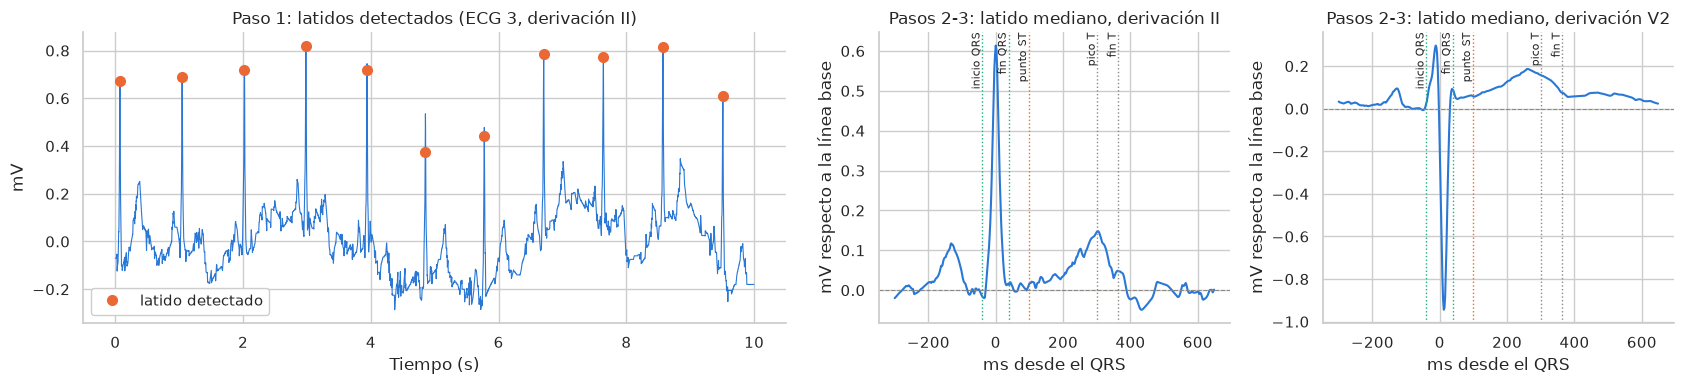

,hr_bpm,rr_std_ms,qrs_ms,qt_ms,r_amp_V5,s_amp_V1,st_V2,t_amp_II
ecg_id,,,,,,,,
3,64.1,20.29,78.0,404.0,0.72,0.72,0.06,0.15


In [3]:
example_id = int(meta.index[meta.scp_codes.map(lambda c: set(c) == {"NORM", "SR"})][0])
signal, fs = read_signal(meta.loc[example_id, "filename_hr"])
peaks = qrs_peaks(signal, fs)
marks = beat_landmarks(signal, fs, peaks)
t_beat = (np.arange(len(marks["corrected"])) - int(0.3 * fs)) / fs * 1000

fig, axes = plt.subplots(1, 3, figsize=(17, 4), gridspec_kw={"width_ratios": [2, 1, 1]})
axes[0].plot(np.arange(len(signal)) / fs, signal[:, 1], color=BLUE, lw=0.8)
axes[0].plot(peaks / fs, signal[peaks, 1], "o", color=ORANGE, ms=7, label="latido detectado")
axes[0].set(title=f"Paso 1: latidos detectados (ECG {example_id}, derivación II)", xlabel="Tiempo (s)", ylabel="mV")
axes[0].legend(loc="lower left", framealpha=0.95)
for ax, lead in zip(axes[1:], ["II", "V2"]):
    j = LEADS.index(lead)
    ax.plot(t_beat, marks["corrected"][:, j], color=BLUE, lw=1.5)
    ax.axhline(0, color=GRAY, lw=0.8, ls="--")
    for key, label, color in [("onset", "inicio QRS", AQUA), ("offset", "fin QRS", AQUA),
                              ("st", "punto ST", ORANGE), ("t_peak", "pico T", GRAY), ("t_end", "fin T", GRAY)]:
        ax.axvline(t_beat[marks[key]], color=color, lw=1, ls=":")
        ax.text(t_beat[marks[key]], ax.get_ylim()[1], label, rotation=90, va="top", ha="right", fontsize=8)
    ax.set(title=f"Pasos 2-3: latido mediano, derivación {lead}", xlabel="ms desde el QRS", ylabel="mV respecto a la línea base")
plt.tight_layout(); plt.show()
display(measures.loc[[example_id], ["hr_bpm", "rr_std_ms", "qrs_ms", "qt_ms", "r_amp_V5", "s_amp_V1", "st_V2", "t_amp_II"]].round(2))

## 3. ¿Las mediciones tienen sentido clínico?

Antes de usar estas medidas hay que comprobar que miden lo que dicen medir. PTB-XL tiene diagnósticos
escritos por cardiólogos, así que podemos comparar grupos donde ya sabemos qué esperar:

- Un QRS normal dura menos de 120 ms; en un bloqueo completo de rama (derecha o izquierda) dura 120 ms o
  más; un bloqueo incompleto queda en medio.
- El QTc normal está alrededor de 400 ms; en el código LNGQT (QT largo) debe superar unos 450-460 ms.
- El índice de Sokolow-Lyon (sección 4) debe ser mayor en hipertrofia ventricular izquierda (LVH).
- El eje que calculamos debe coincidir con el eje anotado por los cardiólogos (`heart_axis`).

"Solo NORM" son los ECG cuya única anotación es NORM (y ritmo sinusal).

,ECG,QRS mediano (ms),% con QRS >= 120 ms
Solo NORM,7257.0,88.0,0.4
Bloqueo incompleto de rama derecha (IRBBB),1118.0,100.0,19.1
Bloqueo completo de rama derecha (CRBBB),541.0,148.0,93.9
Bloqueo de rama izquierda (CLBBB),536.0,172.0,99.3


,QTc mediano (ms),Sokolow-Lyon mediano (mV),ECG
Solo NORM,394.85,2.09,7257
QT largo (LNGQT),467.70,NaN,117
Hipertrofia izquierda (LVH),NaN,3.42,2132


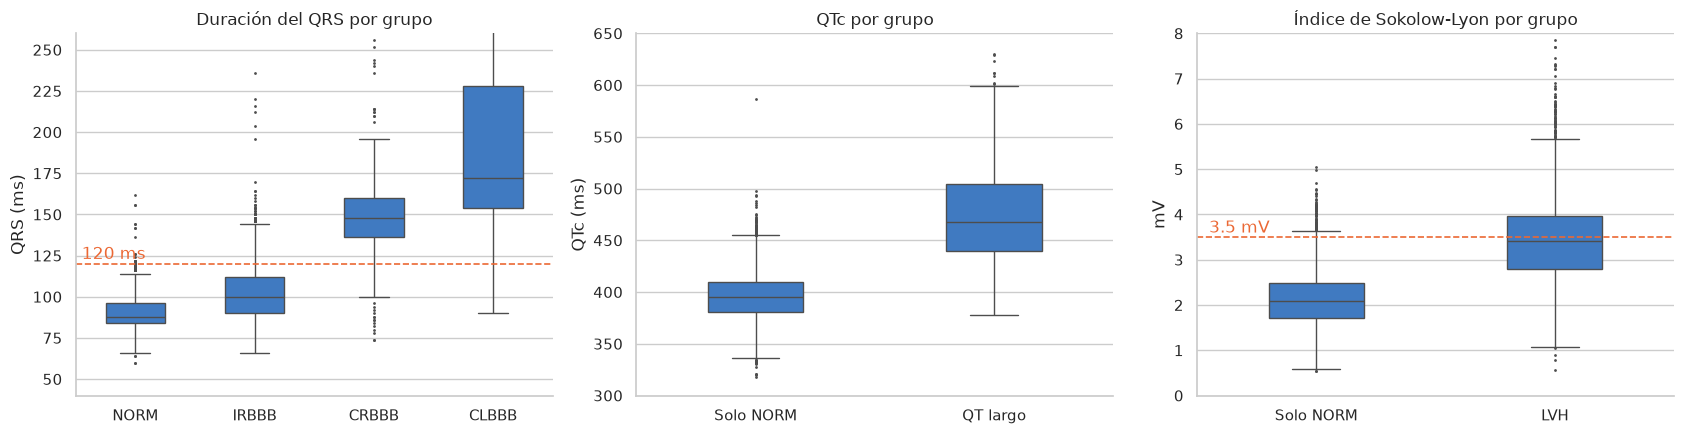

eje calculado,normal,izquierda,derecha,extrema
eje anotado (% por fila),,,,
normal (MID),99.5,0.0,0.4,0.0
izquierda leve (LAD),81.6,18.3,0.1,0.1
izquierda anormal (ALAD),11.4,88.4,0.0,0.3
derecha (RAD),7.2,0.0,91.0,1.8
derecha anormal (ARAD),1.6,7.4,55.7,35.2


ECG con QRS en el límite de búsqueda (350 ms): 49 (0.22%); consistencia mediana entre latidos 0.92 contra 0.99 en el resto


In [4]:
derived = derived_features(measures, meta.sex)
has = lambda code: meta.scp_codes.map(lambda c: code in c)
only_norm = meta.scp_codes.map(lambda c: set(c) <= {"NORM", "SR"})
groups = {"Solo NORM": only_norm, "Bloqueo incompleto de rama derecha (IRBBB)": has("IRBBB"),
          "Bloqueo completo de rama derecha (CRBBB)": has("CRBBB"), "Bloqueo de rama izquierda (CLBBB)": has("CLBBB")}
qrs_check = pd.DataFrame({name: {"ECG": int(mask.sum()), "QRS mediano (ms)": measures.loc[mask, "qrs_ms"].median(),
                                 "% con QRS >= 120 ms": 100 * measures.loc[mask, "qrs_ms"].ge(120).mean()}
                          for name, mask in groups.items()}).T
display(qrs_check.round(1))
other_check = pd.DataFrame({
    "Solo NORM": {"QTc mediano (ms)": derived.loc[only_norm, "qtc_ms"].median(),
                  "Sokolow-Lyon mediano (mV)": derived.loc[only_norm, "sokolow_lyon_mv"].median()},
    "QT largo (LNGQT)": {"QTc mediano (ms)": derived.loc[has("LNGQT"), "qtc_ms"].median(), "Sokolow-Lyon mediano (mV)": np.nan},
    "Hipertrofia izquierda (LVH)": {"QTc mediano (ms)": np.nan, "Sokolow-Lyon mediano (mV)": derived.loc[has("LVH"), "sokolow_lyon_mv"].median()},
}).T
other_check["ECG"] = [only_norm.sum(), has("LNGQT").sum(), has("LVH").sum()]
display(other_check.round(2))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
qrs_long = pd.concat([measures.loc[mask, ["qrs_ms"]].assign(grupo=name.split("(")[-1].rstrip(")")) for name, mask in groups.items()])
qrs_long["grupo"] = qrs_long.grupo.replace({"Solo NORM": "NORM"})
sns.boxplot(data=qrs_long, x="grupo", y="qrs_ms", ax=axes[0], color=BLUE, fliersize=1, width=0.5)
axes[0].axhline(120, color=ORANGE, ls="--", lw=1.2); axes[0].text(-0.45, 123, "120 ms", color=ORANGE, ha="left")
axes[0].set(title="Duración del QRS por grupo", xlabel="", ylabel="QRS (ms)", ylim=(40, 260))
qtc_long = pd.concat([derived.loc[only_norm, ["qtc_ms"]].assign(grupo="Solo NORM"), derived.loc[has("LNGQT"), ["qtc_ms"]].assign(grupo="QT largo")])
sns.boxplot(data=qtc_long, x="grupo", y="qtc_ms", ax=axes[1], color=BLUE, fliersize=1, width=0.4)
axes[1].set(title="QTc por grupo", xlabel="", ylabel="QTc (ms)", ylim=(300, 650))
sok_long = pd.concat([derived.loc[only_norm, ["sokolow_lyon_mv"]].assign(grupo="Solo NORM"), derived.loc[has("LVH"), ["sokolow_lyon_mv"]].assign(grupo="LVH")])
sns.boxplot(data=sok_long, x="grupo", y="sokolow_lyon_mv", ax=axes[2], color=BLUE, fliersize=1, width=0.4)
axes[2].axhline(3.5, color=ORANGE, ls="--", lw=1.2); axes[2].text(-0.45, 3.6, "3.5 mV", color=ORANGE, ha="left")
axes[2].set(title="Índice de Sokolow-Lyon por grupo", xlabel="", ylabel="mV", ylim=(0, 8))
plt.tight_layout(); plt.show()

axis_names = {"MID": "normal (MID)", "LAD": "izquierda leve (LAD)", "ALAD": "izquierda anormal (ALAD)",
              "RAD": "derecha (RAD)", "ARAD": "derecha anormal (ARAD)"}
axis_table = pd.crosstab(meta.heart_axis.map(axis_names), axis_category(derived.qrs_axis_deg), normalize="index") * 100
axis_table = axis_table.loc[list(axis_names.values()), ["normal", "izquierda", "derecha", "extrema"]]
display(axis_table.round(1).rename_axis(index="eje anotado (% por fila)", columns="eje calculado"))
at_limit = measures.qrs_ms.ge(348)
print(f"ECG con QRS en el límite de búsqueda (350 ms): {at_limit.sum()} ({100 * at_limit.mean():.2f}%); "
      f"consistencia mediana entre latidos {measures.loc[at_limit, 'beat_consistency'].median():.2f} "
      f"contra {measures.loc[~at_limit, 'beat_consistency'].median():.2f} en el resto")

Qué vemos:

- El QRS ordena bien los grupos. Los ECG normales tienen un QRS mediano de 88 ms; los bloqueos
  incompletos, 100 ms; los bloqueos completos de rama derecha, 148 ms, y los de rama izquierda, 172 ms.
  Superan el límite clínico de 120 ms el 94% de los bloqueos completos de rama derecha y el 99% de los
  de rama izquierda, pero solo el 0.4% de los ECG normales.
- El QTc mediano de los ECG normales es de unos 395 ms (valor típico) y el de QT largo, unos 468 ms.
- El índice de Sokolow-Lyon es claramente mayor en hipertrofia izquierda (3.4 mV contra 2.1 mV).
- El eje calculado coincide con la anotación: 99.5% de los ejes "normal" anotados salen normales,
  88% de los "izquierda anormal" salen a la izquierda y 91% de los "derecha" salen a la derecha. El
  "izquierda leve" (LAD) es una desviación pequeña; con la regla clínica que usamos (normal desde -30°)
  el 82% queda dentro de lo normal, lo cual es esperable.
- Hay un punto débil: 49 ECG (0.2%) tienen un QRS de 350 ms, que es el límite de búsqueda. En ellos el
  algoritmo no encontró el final del QRS; sus latidos son menos parecidos entre sí, señal de ruido. No
  los eliminamos porque son muy pocos y la transformación de la sección 7 reduce el peso de los extremos,
  pero quedan anotados como limitación.

Conclusión del paso: las medidas son aproximaciones de nuestro propio algoritmo y no sustituyen las de un
equipo certificado, pero reproducen los patrones clínicos esperados. Podemos usarlas como base.

## 4. Construcción de características nuevas

Las 52 medidas anteriores son "materia prima". Ahora las combinamos usando conocimiento médico para
crear características que resumen mejor cada tipo de problema. Cada una tiene una razón clínica:

| Característica nueva | Cómo se calcula | Por qué ayuda |
|---|---|---|
| `qtc_ms` | QT / raíz(RR en s) (fórmula de Bazett) | El QT se acorta cuando el corazón late rápido; el QTc permite comparar personas con distinta frecuencia. |
| `rr_cv` | desviación estándar de RR / RR promedio | Variabilidad del ritmo sin depender de la frecuencia. |
| `qrs_axis_deg` | ángulo de (QRS neto en aVF, QRS neto en I) | El eje eléctrico se desvía en bloqueos fasciculares, hipertrofias e infartos. Es una variable intermedia: no entra directo al modelo, se usa para construir las tres siguientes y la categoría del eje. |
| `axis_sin`, `axis_cos` | seno y coseno del eje | El eje es un ángulo: -179° y 179° están juntos. Seno y coseno lo representan sin ese salto (como la hora en un reloj). |
| `sokolow_lyon_mv` | S en V1 + máx(R en V5, R en V6) | Criterio clásico de hipertrofia ventricular izquierda (HYP). |
| `cornell_mv` | R en aVL + S en V3 | Otro criterio de hipertrofia; su umbral depende del sexo. |
| `lvh_sokolow` | 1 si Sokolow-Lyon > 3.5 mV | Discretización con el umbral clínico. |
| `lvh_cornell` | 1 si Cornell > 2.8 mV (hombres) o > 2.0 mV (mujeres) | Discretización con umbral clínico que combina voltaje y sexo. |
| `n_st_elevated` | número de derivaciones con ST > 0.1 mV | La elevación del ST en varias derivaciones sugiere infarto. |
| `n_st_depressed` | número de derivaciones con ST < -0.05 mV | La depresión del ST sugiere isquemia (STTC). |
| `n_t_inverted` | número de derivaciones con T < -0.1 mV (sin contar aVR, III ni V1) | La T invertida sugiere isquemia; en aVR, III y V1 puede ser normal, por eso no se cuentan. |

También preparamos las variables de la persona:

- Edad en grupos (discretización): `< 30`, `30-44`, `45-59`, `60-74`, `75+`. Esto resuelve el problema de
  las edades ocultas (300 = 90 años o más): no conocemos la edad exacta, pero sí sabemos que pertenecen
  al último grupo. Como los grupos tienen un orden natural usamos codificación ordinal (0 a 4). El
  grupo `< 30` es el que corresponde a la población de estudiantes del proyecto (en PTB-XL también
  incluye a 133 menores de 18 años).
- Sexo: PTB-XL ya lo trae como 0 (hombre) y 1 (mujer). Lo renombramos `female` para que sea claro.
  Es una codificación binaria; no hace falta one-hot con solo dos valores.
- Categoría del eje (discretización + one-hot): normal (-30° a 90°), izquierda (-90° a -30°), derecha
  (90° a 180°) o extrema (-180° a -90°). Estas categorías no tienen orden entre sí, así que usamos
  one-hot: una columna 0/1 por categoría. Dejamos "normal" como referencia (sin columna), porque si
  todas las demás valen 0 ya sabemos que el eje es normal.

En total hay 68 características candidatas.

In [5]:
X = pd.concat([measures, derived], axis=1)
X["female"] = meta.sex.astype(float)
X["age_band"] = age_band(meta.age_capped).cat.codes.astype(float)
X.loc[meta.age.eq(300), "age_band"] = len(AGE_LABELS) - 1
assert X.age_band.ge(0).all()
axis_group = axis_category(derived.qrs_axis_deg)
for name in ["izquierda", "derecha", "extrema"]:
    X[f"axis_{name}"] = axis_group.eq(name).astype(float)

GLOBAL = ["hr_bpm", "rr_std_ms", "qrs_ms", "qt_ms"]
PER_LEAD = [f"{kind}_{lead}" for kind in ["r_amp", "s_amp", "st", "t_amp"] for lead in LEADS]
NEW = ["qtc_ms", "rr_cv", "axis_sin", "axis_cos", "sokolow_lyon_mv", "cornell_mv",
       "n_st_elevated", "n_st_depressed", "n_t_inverted"]
ORDINAL = ["age_band"]
BINARY = ["female", "lvh_sokolow", "lvh_cornell", "axis_izquierda", "axis_derecha", "axis_extrema"]
CANDIDATES = GLOBAL + PER_LEAD + NEW + ORDINAL + BINARY
print("Características candidatas:", len(CANDIDATES))

data = X.loc[keep, CANDIDATES]
Y = Y_all.loc[keep]
split = split_all.loc[keep]
train, val = split.eq("entrenamiento"), split.eq("validación")

display(pd.DataFrame({"grupo de edad": AGE_LABELS, "código ordinal": range(len(AGE_LABELS)),
                      "ECG": [int(data.age_band.eq(i).sum()) for i in range(len(AGE_LABELS))]}).set_index("grupo de edad"))
display(axis_group[keep].value_counts().to_frame("ECG por categoría de eje"))

summary_new = pd.DataFrame({sc: data.loc[Y[sc].eq(1), ["qrs_ms", "qtc_ms", "sokolow_lyon_mv", "n_st_elevated",
                                                         "n_st_depressed", "n_t_inverted"]].mean() for sc in SUPERCLASSES})
summary_new.loc["% lvh_sokolow"] = [100 * data.loc[Y[sc].eq(1), "lvh_sokolow"].mean() for sc in SUPERCLASSES]
summary_new.loc["% eje izquierda"] = [100 * data.loc[Y[sc].eq(1), "axis_izquierda"].mean() for sc in SUPERCLASSES]
print("Promedio de algunas características nuevas en cada superclase (los grupos se solapan):")
display(summary_new.round(2))

norm_people = pd.DataFrame({"sexo": meta.sex.map({0: "hombre", 1: "mujer"}),
                            "edad": np.where(meta.age_capped.lt(30), "< 30", "30 o más"),
                            "derivaciones con ST elevado": derived.n_st_elevated,
                            "% con ST elevado en V2": 100 * measures.st_V2.gt(0.1)})[only_norm & meta.age_capped.notna()]
print("ECG solo NORM: elevación del ST por sexo y edad")
display(norm_people.groupby(["sexo", "edad"]).agg(ECG=("sexo", "size"), **{
    "derivaciones con ST elevado (promedio)": ("derivaciones con ST elevado", "mean"),
    "% con ST elevado en V2": ("% con ST elevado en V2", "mean")}).round(2))

Características candidatas: 68


,código ordinal,ECG
grupo de edad,,
< 30,0,1370
30-44,1,2557
45-59,2,5702
60-74,3,7299
75+,4,4459


,ECG por categoría de eje
qrs_axis_deg,
normal,18707
izquierda,2190
derecha,406
extrema,84


Promedio de algunas características nuevas en cada superclase (los grupos se solapan):


,NORM,MI,STTC,CD,HYP
qrs_ms,89.97,103.97,95.85,121.26,101.78
qtc_ms,395.85,421.47,426.03,427.62,418.04
sokolow_lyon_mv,2.14,2.03,2.44,2.02,3.15
n_st_elevated,1.20,1.53,1.14,1.97,1.91
n_st_depressed,0.20,1.43,2.11,1.76,2.48
n_t_inverted,0.01,1.03,1.08,0.99,1.42
% lvh_sokolow,2.05,5.87,13.09,7.68,38.17
% eje izquierda,0.40,20.98,9.48,35.91,11.21


ECG solo NORM: elevación del ST por sexo y edad


ECG  derivaciones con ST elevado (promedio)  % con ST elevado en V2
sexo   edad                                                                          
hombre 30 o más  2944                                    1.75                   72.01
       < 30       324                                    2.85                   93.83
mujer  30 o más  3416                                    0.62                   36.56
       < 30       552                                    0.86                   51.45

La tabla confirma que cada característica nueva "apunta" a la superclase para la que fue pensada:

- El QRS es mucho más largo en CD (trastornos de conducción, 121 ms en promedio) que en NORM (90 ms).
- Las derivaciones con ST deprimido y con T invertida casi no aparecen en NORM y aumentan en todas las
  anomalías, sobre todo en STTC e HYP.
- El índice de Sokolow-Lyon es mayor en HYP, y la bandera `lvh_sokolow` se activa en 38% de los ECG con
  HYP contra 2% en NORM.
- El eje desviado a la izquierda aparece en 36% de CD y 21% de MI, contra 0.4% en NORM.
- La elevación del ST también aparece en ECG normales (1.2 derivaciones en promedio). La segunda tabla
  muestra de dónde viene: en hombres menores de 30 años con ECG normal hay en promedio 2.85 derivaciones
  con ST elevado, y el 94% tiene el ST elevado en V2. En mujeres jóvenes el promedio es 0.86. Es un
  patrón conocido y normal en hombres jóvenes. Para el proyecto es una advertencia importante: en una
  población de estudiantes, `n_st_elevated` por sí sola marcaría como sospechosos a muchos hombres
  sanos, así que su uso debe revisarse con el cardiólogo.

## 5. Valores faltantes

Solo 5 ECG (taquicardias de 155 a 179 lpm con bloqueo de rama) no tienen espacio para una onda T antes del
siguiente latido, así que su QT, QTc y amplitudes de T quedaron vacíos. Son el 0.02% de los datos. Los
rellenamos con la mediana de entrenamiento. No añadimos columnas indicadoras de ausencia, porque una
columna con 5 unos no aporta información y el filtro de varianza la eliminaría.

In [6]:
missing = data.isna().sum()
display(missing[missing.gt(0)].to_frame("valores vacíos").T)
no_t = data.index[data.qt_ms.isna()]
display(pd.DataFrame({"frecuencia (lpm)": measures.loc[no_t, "hr_bpm"].round(0), "QRS (ms)": measures.loc[no_t, "qrs_ms"],
                      "códigos SCP": meta.loc[no_t, "scp_codes"].map(lambda c: ", ".join(c))}))
train_medians = data[train].median()
data = data.fillna(train_medians)
assert data.notna().all().all()

,qt_ms,t_amp_I,t_amp_II,t_amp_III,t_amp_aVR,t_amp_aVL,t_amp_aVF,t_amp_V1,t_amp_V2,t_amp_V3,t_amp_V4,t_amp_V5,t_amp_V6,qtc_ms,n_t_inverted
valores vacíos,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5


,frecuencia (lpm),QRS (ms),códigos SCP
ecg_id,,,
7960,155.0,274.0,"CLBBB, SVTAC"
11828,169.0,242.0,"CLBBB, AFIB"
12394,163.0,350.0,"CRBBB, AFIB"
13112,179.0,350.0,"CRBBB, LPFB, ABQRS, AFIB"
15838,163.0,230.0,"ASMI, ILBBB, ANEUR, AFIB"


## 6. Selección, paso 1: filtro de varianza

Una característica que casi siempre vale lo mismo no ayuda a distinguir a nadie, pero sí ocupa espacio y
añade ruido. Para cada característica calculamos qué porcentaje de ECG de entrenamiento comparten el
valor más frecuente. Si es más de 99%, la característica es casi constante y se elimina.

Usamos esta regla en lugar de un umbral de varianza fijo porque las variables tienen unidades distintas
(ms, mV, conteos): una varianza de 0.01 es enorme para una amplitud en mV y diminuta para una duración en
ms. El porcentaje del valor más frecuente no depende de las unidades. En variables 0/1 es equivalente a
un umbral de varianza de 0.0099 (p × (1 - p) con p = 1%).

In [7]:
dominant = data[train].apply(lambda col: col.value_counts(normalize=True).iloc[0])
variance_table = pd.DataFrame({"% del valor más frecuente": 100 * dominant, "varianza": data[train].var()})
display(variance_table.sort_values("% del valor más frecuente", ascending=False).head(8).round(4))
quasi_constant = dominant.index[dominant.gt(0.99)].tolist()
features = [c for c in CANDIDATES if c not in quasi_constant]
binary_check = VarianceThreshold(threshold=0.01 * 0.99).fit(data.loc[train, BINARY])
print("Comprobación con VarianceThreshold (umbral 0.0099) en las 0/1, elimina:",
      [c for c, ok in zip(BINARY, binary_check.get_support()) if not ok])
print("Eliminadas por ser casi constantes:", quasi_constant)
print("Quedan:", len(features))

,% del valor más frecuente,varianza
axis_extrema,99.6254,0.0037
axis_derecha,98.0975,0.0187
lvh_sokolow,93.1569,0.0638
lvh_cornell,89.7442,0.0920
axis_izquierda,89.6681,0.0926
n_t_inverted,81.9353,1.7858
n_st_depressed,65.9252,3.1581
female,52.0225,0.2496


Comprobación con VarianceThreshold (umbral 0.0099) en las 0/1, elimina: ['axis_extrema']
Eliminadas por ser casi constantes: ['axis_extrema']
Quedan: 67


Solo se elimina `axis_extrema`: apenas 0.37% de los ECG tienen eje extremo. Las demás columnas 0/1, como
`axis_derecha` (1.9%), sí varían lo suficiente para conservarse en este paso.

## 7. Transformaciones para reducir la asimetría

Muchas medidas tienen colas largas: la mayoría de los ECG tiene un QRS de 80-100 ms, pero unos pocos
llegan a 200 ms. La asimetría (skewness) mide esa cola: 0 es simétrico y más de 1 (o menos de -1) se
considera muy asimétrico. Las colas largas afectan a los modelos lineales, al ANOVA y al PCA, porque unos
pocos valores extremos dominan los promedios y las varianzas.

Comparamos las transformaciones comunes en los datos de entrenamiento:

- log1p y raíz cuadrada: solo funcionan con valores mayores o iguales a 0.
- Box-Cox: solo funciona con valores estrictamente positivos.
- Yeo-Johnson: funciona con cualquier valor, incluso negativos y ceros. Es importante aquí porque el ST,
  la onda T y el eje toman valores negativos.

Regla: si la asimetría en entrenamiento es mayor que 1 en valor absoluto, aplicamos Yeo-Johnson. Su
parámetro se ajusta solo con entrenamiento. La edad (ordinal) y las variables 0/1 no se transforman.
En las gráficas, los valores transformados se muestran estandarizados (media 0, desviación 1) para que
sean legibles; el escalamiento se explica en la sección 8.

Variables continuas: 61; con |asimetría| > 1: 45


,original,log1p,raiz_cuadrada,box_cox,yeo_johnson
st_V3,5.44,NaN,NaN,NaN,-0.81
st_V2,4.94,NaN,NaN,NaN,-1.45
st_V1,4.54,NaN,NaN,NaN,-1.35
qrs_ms,4.20,2.19,3.03,0.00,0.00
qtc_ms,3.95,2.64,3.27,-0.26,-0.26
st_V4,3.64,NaN,NaN,NaN,-0.68
s_amp_V6,3.49,2.25,1.12,NaN,0.24
r_amp_V1,3.47,2.28,1.30,NaN,0.19
st_aVL,-3.38,NaN,NaN,NaN,0.58
st_III,3.38,NaN,NaN,NaN,-0.65


,original,log1p,raiz_cuadrada,box_cox,yeo_johnson
variables donde se puede aplicar (de 61),61,35,35,8,61


Variables donde otra transformación deja menos asimetría que Yeo-Johnson (por más de 0.01):


,original,log1p,raiz_cuadrada,box_cox,yeo_johnson
rr_std_ms,2.677,0.390,1.476,0.009,0.023
rr_cv,2.322,2.152,1.462,0.024,0.670


,|asimetría| mediana,variables con |asimetría| > 1
antes,2.04,45
después de Yeo-Johnson,0.19,3


Siguen asimétricas: {'st_V1': -1.35, 'st_V2': -1.45, 'n_t_inverted': 1.66}


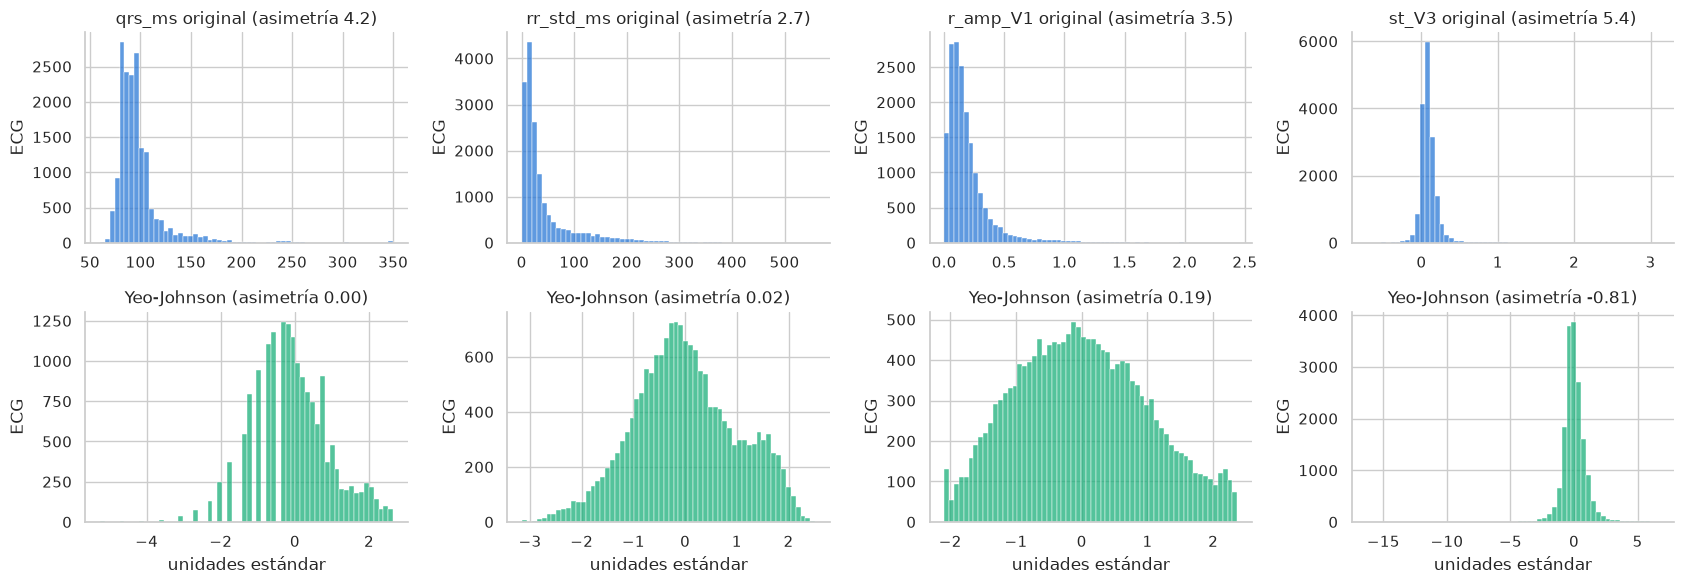

In [8]:
continuous = [c for c in features if c not in ORDINAL + BINARY]
skews = skew_table(data.loc[train, continuous])
skewed = skews.index[skews.original.abs().gt(1)].tolist()
print(f"Variables continuas: {len(continuous)}; con |asimetría| > 1: {len(skewed)}")
display(skews.sort_values("original", key=abs, ascending=False).head(12).round(2))
display(skews.notna().sum().to_frame(f"variables donde se puede aplicar (de {len(continuous)})").T)
other_best = skews[["log1p", "raiz_cuadrada", "box_cox"]].abs().min(axis=1)
print("Variables donde otra transformación deja menos asimetría que Yeo-Johnson (por más de 0.01):")
display(skews.loc[skews.yeo_johnson.abs().gt(other_best + 0.01)].round(3))

power = PowerTransformer(method="yeo-johnson", standardize=True).fit(data.loc[train, skewed])
transformed = data[features].copy()
transformed[skewed] = power.transform(data[skewed])
after = transformed.loc[train, skewed].skew()
display(pd.DataFrame({"|asimetría| mediana": [skews.loc[skewed, "original"].abs().median(), after.abs().median()],
                      "variables con |asimetría| > 1": [len(skewed), int(after.abs().gt(1).sum())]},
                     index=["antes", "después de Yeo-Johnson"]).round(2))
print("Siguen asimétricas:", after[after.abs().gt(1)].round(2).to_dict())

show = ["qrs_ms", "rr_std_ms", "r_amp_V1", "st_V3"]
fig, axes = plt.subplots(2, len(show), figsize=(17, 6))
for j, col in enumerate(show):
    sns.histplot(data.loc[train, col], bins=60, ax=axes[0, j], color=BLUE)
    sns.histplot(transformed.loc[train, col], bins=60, ax=axes[1, j], color=AQUA)
    axes[0, j].set(title=f"{col} original (asimetría {skews.loc[col, 'original']:.1f})", xlabel="", ylabel="ECG")
    axes[1, j].set(title=f"Yeo-Johnson (asimetría {after[col]:.2f})", xlabel="unidades estándar", ylabel="ECG")
plt.tight_layout(); plt.show()

Qué vemos:

- 45 de las 61 variables continuas eran muy asimétricas. Después de Yeo-Johnson la asimetría típica
  baja de unos 2 a unos 0.2, y las distribuciones se ven mucho más simétricas.
- Las otras transformaciones no alcanzan: Box-Cox solo se puede aplicar a 8 de las 61 variables y
  log1p o raíz cuadrada a 35, porque las demás tienen valores negativos o ceros (las celdas vacías de la
  tabla). Yeo-Johnson se puede aplicar a las 61. Donde las otras también funcionan, Yeo-Johnson deja una
  asimetría igual o menor, con dos excepciones: en `rr_std_ms` y `rr_cv` Box-Cox queda mejor. Ambas se
  eliminan después por baja relevancia (sección 9), así que preferimos una sola transformación para
  todas: el procedimiento es más simple y fácil de repetir.
- Tres variables siguen algo asimétricas: el ST en V1 y V2 y el conteo de ondas T invertidas. El conteo
  vale 0 en más de 80% de los ECG; ninguna transformación puede volver normal una variable donde la
  mayoría de los valores son idénticos. Lo aceptamos: el objetivo es reducir el peso de los extremos, no
  forzar una campana perfecta.

## 8. Escalamiento

Las variables están en unidades muy distintas: la frecuencia va de 40 a 150 lpm, el QRS de 60 a 200 ms y
las amplitudes de -1 a 3 mV. Para modelos como la regresión logística, las máquinas de soporte vectorial,
los vecinos cercanos o el PCA, una variable con números grandes pesaría más solo por su unidad. El
escalamiento pone a todas en la misma escala.

Opciones comunes:

- Min-max lleva cada variable al rango 0 a 1. Su problema es que depende del mínimo y del máximo, y
  en un ECG hay valores extremos reales (el Avance 1.8 encontró 47 ECG con picos de más de 10 mV). Un solo
  extremo aplasta a todos los demás valores en una franja estrecha.
- Estandarización (z-score) resta la media y divide entre la desviación estándar. Después de
  Yeo-Johnson las colas ya están controladas, así que la estandarización es estable.

Elegimos estandarización, ajustada con entrenamiento. La siguiente celda muestra el problema de min-max
con datos reales: qué porcentaje de los ECG queda apretado en el primer 20% del rango.

In [9]:
minmax = MinMaxScaler().fit(data.loc[train, continuous])
squeezed = pd.Series((minmax.transform(data.loc[train, continuous]) <= 0.2).mean(axis=0) * 100, index=continuous)
display(squeezed.sort_values(ascending=False).head(6).round(1).to_frame("% de ECG en el primer 20% del rango min-max"))

scaler = StandardScaler().fit(transformed.loc[train, features])
scaled = pd.DataFrame(scaler.transform(transformed[features]), index=transformed.index, columns=features)
check = scaled[train].agg(["mean", "std"]).T
print(f"Entrenamiento después de escalar: medias entre {check['mean'].min():.3f} y {check['mean'].max():.3f}, "
      f"desviaciones entre {check['std'].min():.3f} y {check['std'].max():.3f}")
means, stds = scaled.groupby(split).mean().T, scaled.groupby(split).std().T
display(pd.DataFrame({"media más baja": means.min(), "media más alta": means.max(),
                      "desviación más baja": stds.min(), "desviación más alta": stds.max()}).T.round(3)
        [["entrenamiento", "validación", "prueba"]])

,% de ECG en el primer 20% del rango min-max
s_amp_I,99.7
s_amp_V6,97.8
s_amp_V4,95.1
s_amp_aVL,94.7
s_amp_V5,94.1
r_amp_V1,94.0


Entrenamiento después de escalar: medias entre -0.000 y 0.000, desviaciones entre 1.000 y 1.000


,entrenamiento,validación,prueba
media más baja,-0.0,-0.086,-0.066
media más alta,0.0,0.082,0.072
desviación más baja,1.0,0.888,0.898
desviación más alta,1.0,1.083,1.174


Con min-max, en las variables con extremos casi todos los ECG quedarían concentrados en una pequeña parte
del rango, y el modelo vería poca diferencia entre ellos. Con la estandarización, en entrenamiento todas las
variables tienen media 0 y desviación 1. En validación y prueba las medias quedan cerca de 0 pero no son
exactamente 0, y las desviaciones quedan cerca de 1 sin ser exactamente 1. Es lo correcto: esos
conjuntos no participaron en el ajuste.

Nota: escalamos también las columnas 0/1 y la edad ordinal. Así el PCA y los modelos lineales las tratan
con el mismo peso que el resto. El valor original queda guardado en `data`.

## 9. Selección, paso 2: relevancia (ANOVA y chi-cuadrado)

Ahora preguntamos: ¿cada característica cambia entre los ECG que tienen y no tienen cada superclase?

- Para las variables numéricas usamos ANOVA (prueba F). Como hay 17 mil ECG de entrenamiento, casi
  cualquier diferencia minúscula resulta "significativa" (p < 0.05). Por eso no decidimos con el p-valor
  sino con el tamaño del efecto eta², que es la proporción de la variación de la característica que se
  explica por tener o no la superclase. Usamos el umbral convencional de efecto pequeño: eta² ≥ 0.01.
- Para las variables 0/1 usamos chi-cuadrado y su tamaño de efecto, la V de Cramér, con el umbral
  convencional de efecto pequeño: V ≥ 0.1.

Una característica se queda si alcanza el umbral en al menos una de las cinco superclases. Así no
perdemos una variable que solo sirve para un problema (por ejemplo, el QRS solo para CD). Su "relevancia"
es el mayor valor entre las cinco. Para poder comparar ambos tipos usamos V² en las 0/1, que en una tabla
de 2 × 2 equivale a eta². Esta relevancia sirve en el paso siguiente para decidir cuál conservar de un
par redundante.

Otra razón para no decidir con p-valores: algunos pacientes tienen varios ECG, y las pruebas suponen
que todos los ECG son independientes. El tamaño del efecto es mucho menos sensible a eso.

Numéricas con p < 0.05 en alguna superclase: 62 de 62


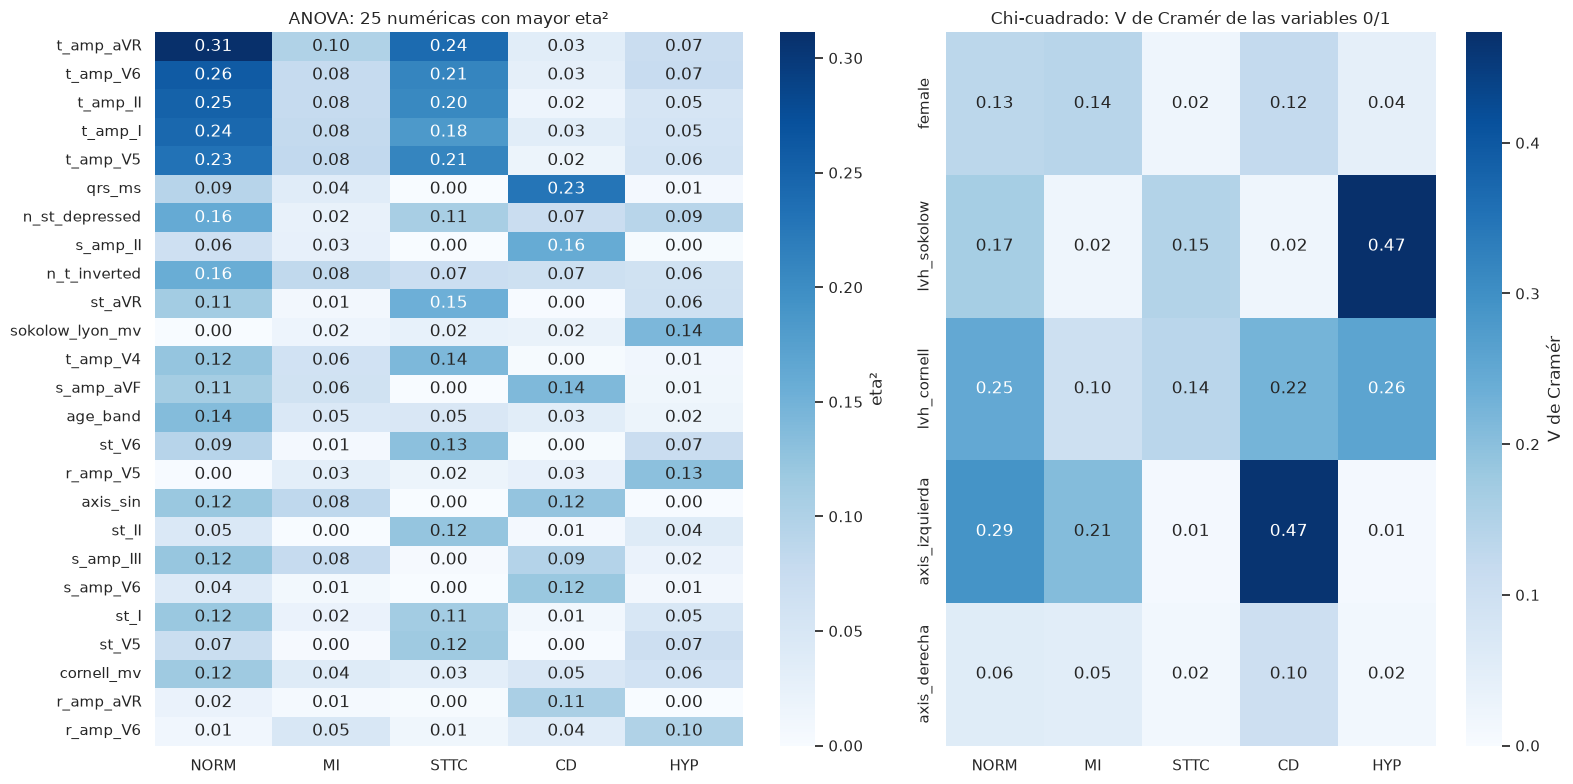

p-valores de chi-cuadrado (variables 0/1):


,NORM,MI,STTC,CD,HYP
female,2.8e-68,5.0e-75,2.7e-03,8.9e-57,9.2e-09
lvh_sokolow,2.2e-104,2.5e-03,3.1e-82,3.4e-03,0.0e+00
lvh_cornell,3.7e-232,6.0e-40,4.4e-70,3.3e-188,3.4e-249
axis_izquierda,0.0e+00,9.0e-164,1.1e-01,0.0e+00,1.1e-01
axis_derecha,6.6e-14,2.2e-12,2.2e-02,7.2e-42,2.0e-02


Relevantes: 62 de 67. Eliminadas por relevancia baja:


,mayor eta²,superclase
rr_std_ms,0.00196,STTC
t_amp_III,0.00516,CD
st_V2,0.00824,STTC
qt_ms,0.00972,CD
rr_cv,0.00997,STTC


In [10]:
numeric = [c for c in features if c not in BINARY]
binary = [c for c in features if c in BINARY]
f_pvalues = pd.DataFrame({sc: f_classif(scaled.loc[train, numeric], Y.loc[train, sc])[1] for sc in SUPERCLASSES}, index=numeric)
print(f"Numéricas con p < 0.05 en alguna superclase: {int(f_pvalues.lt(0.05).any(axis=1).sum())} de {len(numeric)}")

eta = eta_squared(scaled.loc[train, numeric], Y.loc[train])
cramer = pd.DataFrame({sc: {b: cramers_v(data.loc[train, b], Y.loc[train, sc]) for b in binary} for sc in SUPERCLASSES})
chi_p = pd.DataFrame({sc: {b: chi2_contingency(pd.crosstab(data.loc[train, b], Y.loc[train, sc]), correction=False)[1]
                            for b in binary} for sc in SUPERCLASSES})

fig, axes = plt.subplots(1, 2, figsize=(16, 8), gridspec_kw={"width_ratios": [1.2, 1]})
top = eta.max(axis=1).sort_values(ascending=False).index[:25]
sns.heatmap(eta.loc[top], annot=True, fmt=".2f", cmap="Blues", vmin=0, ax=axes[0], cbar_kws={"label": "eta²"})
axes[0].set(title="ANOVA: 25 numéricas con mayor eta²", xlabel="", ylabel="")
sns.heatmap(cramer, annot=True, fmt=".2f", cmap="Blues", vmin=0, ax=axes[1], cbar_kws={"label": "V de Cramér"})
axes[1].set(title="Chi-cuadrado: V de Cramér de las variables 0/1", xlabel="", ylabel="")
plt.tight_layout(); plt.show()
print("p-valores de chi-cuadrado (variables 0/1):")
display(chi_p.map(lambda p: f"{p:.1e}"))

relevance = pd.concat([eta.max(axis=1), cramer.max(axis=1) ** 2])
relevant = eta.index[eta.max(axis=1).ge(0.01)].tolist() + cramer.index[cramer.max(axis=1).ge(0.1)].tolist()
dropped = pd.DataFrame({"mayor eta²": eta.max(axis=1), "superclase": eta.idxmax(axis=1)}).loc[lambda d: d["mayor eta²"].lt(0.01)]
print(f"Relevantes: {len(relevant)} de {len(features)}. Eliminadas por relevancia baja:")
display(dropped.sort_values("mayor eta²").round(5))

Qué vemos:

- Todas las numéricas tienen p < 0.05 en alguna superclase, lo que confirma que el p-valor no sirve para
  filtrar con tantos datos. El tamaño del efecto sí separa.
- Las características más relevantes son las que esperaría un cardiólogo: la amplitud de la onda T (sobre
  todo en aVR, V6, II y I), la duración del QRS, el número de derivaciones con ST deprimido y con T
  invertida, el índice de Sokolow-Lyon y la edad. Varias de ellas son características nuevas de la
  sección 4.
- Entre las 0/1, `lvh_sokolow` se asocia sobre todo con HYP (V = 0.47) y el eje a la izquierda con CD
  (V = 0.47). Todas las 0/1 superan el umbral en alguna superclase.
- Se eliminan 5 características. `qt_ms` y `rr_cv` quedan justo por debajo del umbral (por eso la tabla
  muestra cinco decimales). `qt_ms` sale porque el QT sin corregir depende mucho de la frecuencia; su
  versión corregida `qtc_ms` sí se queda. `rr_std_ms` y `rr_cv` miden irregularidad del ritmo, que no
  forma parte de ninguna de las cinco superclases diagnósticas (los ritmos se anotan aparte en PTB-XL).
  `st_V2` y `t_amp_III` tienen un efecto muy pequeño.

## 10. Selección, paso 3: correlación (redundancia)

Dos características muy correlacionadas dicen casi lo mismo. Conservar las dos ocupa espacio, hace más
lento el entrenamiento y vuelve inestables los coeficientes de los modelos lineales.

En el ECG hay una razón física para esperar redundancia: las seis derivaciones de los miembros (I, II,
III, aVR, aVL, aVF) se calculan a partir de solo dos señales. Por ejemplo, aVR = -(I + II) / 2. La
siguiente gráfica lo muestra con la amplitud de la onda T.

Usamos la correlación de Spearman (no exige relaciones lineales) en entrenamiento. Recorremos las
características de la más relevante a la menos relevante. Una característica se elimina si su
correlación absoluta con alguna ya conservada supera el umbral. Así, en cada par redundante sobrevive la
más relevante.

Para elegir el umbral sin adivinar, probamos varios y medimos con un modelo sencillo (regresión logística,
una por superclase) el área bajo la curva ROC (AUC) en validación. El AUC es la probabilidad de que el
modelo le dé una puntuación más alta a un ECG con la superclase que a uno sin ella: 0.5 es azar y 1 es
perfecto. Reportamos el promedio de las cinco superclases.
La regla es: elegir el conjunto más pequeño cuya AUC promedio no baje más de 0.005 respecto a no
filtrar por correlación.

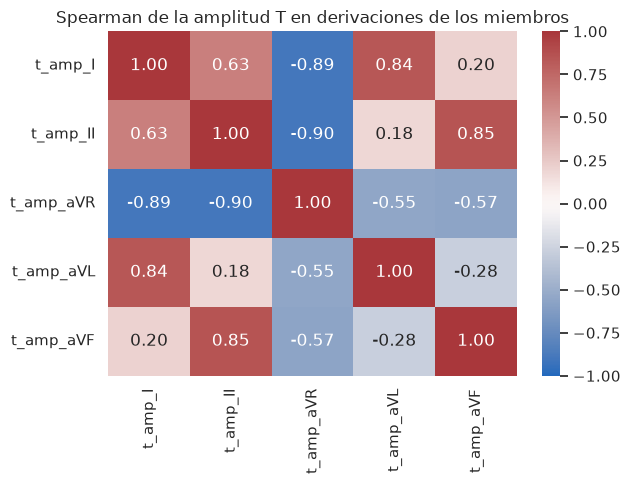

AUC macro sin filtro de correlación (62 características): 0.8842


,n_caracteristicas,AUC_macro,diferencia_vs_sin_filtro
umbral,,,
0.95,62,0.8842,0.0000
0.90,61,0.8842,-0.0001
0.85,52,0.8815,-0.0027
0.80,47,0.8806,-0.0037
0.75,42,0.8782,-0.0060
0.70,37,0.8771,-0.0072


Umbral elegido: 0.8. Se eliminan 15 características redundantes:


,eliminada,se_conserva,correlacion_abs
0,t_amp_V6,t_amp_aVR,0.918
1,t_amp_II,t_amp_aVR,0.896
2,t_amp_I,t_amp_aVR,0.894
3,t_amp_V5,t_amp_aVR,0.867
4,st_V6,st_aVR,0.867
5,st_II,st_aVR,0.871
6,s_amp_III,axis_sin,0.827
7,st_I,st_aVR,0.854
8,st_V5,st_aVR,0.829
9,r_amp_V6,r_amp_V5,0.854


In [11]:
corr = scaled.loc[train, relevant].corr(method="spearman").abs()
limb_t = [f"t_amp_{lead}" for lead in ["I", "II", "III", "aVR", "aVL", "aVF"] if f"t_amp_{lead}" in relevant]
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(scaled.loc[train, limb_t].corr(method="spearman"), annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, center=0, ax=ax)
ax.set_title("Spearman de la amplitud T en derivaciones de los miembros")
plt.tight_layout(); plt.show()

reference = validation_auc(scaled[relevant], Y, train, val)["AUC_macro"]
threshold_rows = []
for threshold in [0.95, 0.9, 0.85, 0.8, 0.75, 0.7]:
    kept, _ = drop_redundant(corr, relevance[relevant], threshold)
    threshold_rows.append({"umbral": threshold, **validation_auc(scaled[kept], Y, train, val)})
threshold_table = pd.DataFrame(threshold_rows).set_index("umbral")
threshold_table["diferencia_vs_sin_filtro"] = threshold_table.AUC_macro - reference
print(f"AUC macro sin filtro de correlación ({len(relevant)} características): {reference:.4f}")
display(threshold_table[["n_caracteristicas", "AUC_macro", "diferencia_vs_sin_filtro"]].round(4))

acceptable = threshold_table[threshold_table.diferencia_vs_sin_filtro.ge(-0.005)]
CORR_THRESHOLD = float(acceptable.n_caracteristicas.idxmin())
selected, removed = drop_redundant(corr, relevance[relevant], CORR_THRESHOLD)
print(f"Umbral elegido: {CORR_THRESHOLD}. Se eliminan {len(removed)} características redundantes:")
display(removed.round(3))

Qué vemos:

- La amplitud T en aVR está casi en espejo con la de I y II (correlaciones de -0.89 y -0.90), tal como
  predice aVR = -(I + II) / 2. Es redundancia física, no casualidad.
- La tabla de umbrales permite escoger con evidencia. Al bajar el umbral se eliminan más
  características y el AUC baja poco a poco. El umbral elegido es 0.80: deja 47 características y el
  AUC baja solo 0.004 (de 0.884 a 0.881). Con 0.75 la pérdida ya supera 0.005.
- Las 15 eliminadas caen en tres grupos:
  - medidas de derivaciones de los miembros que ya contiene otra (aVR = -(I + II) / 2 y
    aVF = (II + III) / 2);
  - medidas de V5 y V6, que miran la cara lateral del corazón; aVR la mira desde el lado opuesto, por eso
    sus valores son casi un espejo. También se eliminan precordiales que repiten a su vecina (V3 con V4,
    V6 con V5);
  - medidas que ya quedaron dentro de una característica nueva: `s_amp_III` y `r_amp_aVF` dentro del
    eje, y `s_amp_V3` dentro del índice de Cornell. Que sobrevivan las características nuevas y no las
    medidas sueltas confirma que la construcción de la sección 4 resume bien la información.

## 11. Extracción de características con PCA

La selección conserva columnas originales y fáciles de interpretar. La extracción, en cambio, crea
columnas nuevas que combinan a todas. El análisis de componentes principales (PCA) busca las direcciones
en las que los datos varían más y las ordena: la primera componente resume la mayor variación posible,
la segunda la mayor variación restante, y así sucesivamente. Si pocas componentes explican casi toda la
variación, podemos guardar menos columnas.

Aplicamos PCA a las características seleccionadas, ya escaladas (el PCA exige variables en la misma
escala), y lo ajustamos solo con entrenamiento.

También probamos el análisis factorial (FA). El FA busca factores "ocultos" que expliquen las
correlaciones y supone un modelo estadístico sobre ellos. Nuestro objetivo es comprimir para la fase de
modelado, no interpretar factores latentes, así que esperamos que el PCA sea la opción más directa. La
segunda celda de esta sección lo comprueba con datos.

47 características seleccionadas. Componentes para explicar 90%: 22; para 95%: 28
Variación explicada por las 5 primeras componentes (%): [16.5 12.8 10.2  8.5  6.8]


,PC1,PC2,PC3
1° mayor peso,cornell_mv,sokolow_lyon_mv,st_V4
2° mayor peso,axis_sin,s_amp_V1,s_amp_aVL
3° mayor peso,s_amp_aVF,st_V1,s_amp_I
4° mayor peso,s_amp_V4,t_amp_V1,t_amp_V4
5° mayor peso,s_amp_II,s_amp_aVR,r_amp_aVR
6° mayor peso,axis_izquierda,s_amp_V2,axis_cos


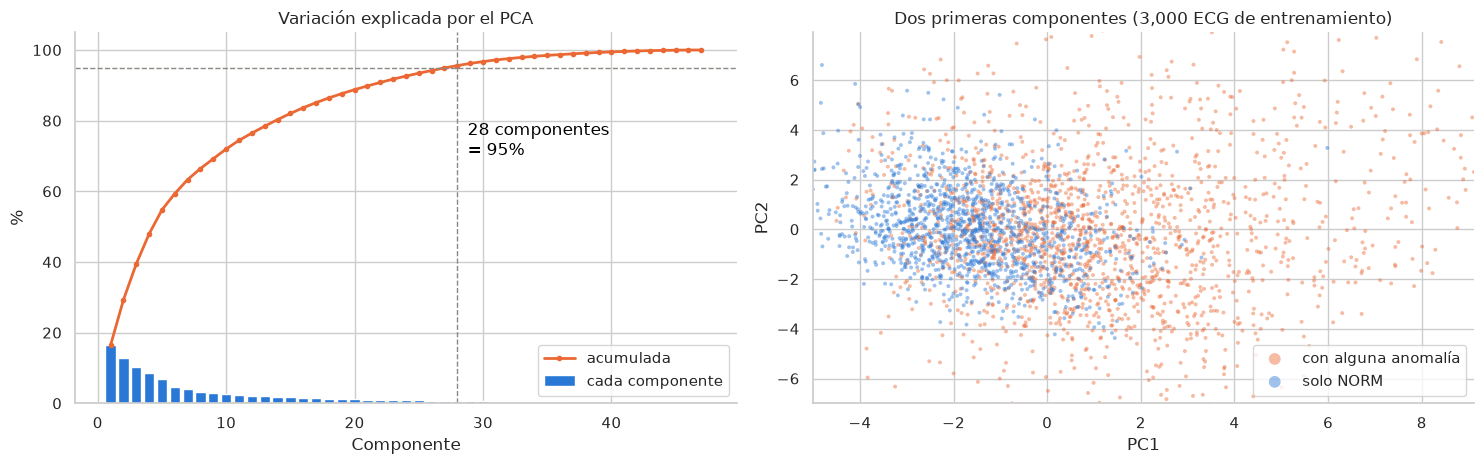

In [12]:
pca_full = PCA().fit(scaled.loc[train, selected])
cumulative = np.cumsum(pca_full.explained_variance_ratio_)
n90, n95 = int(np.searchsorted(cumulative, 0.90) + 1), int(np.searchsorted(cumulative, 0.95) + 1)
print(f"{len(selected)} características seleccionadas. Componentes para explicar 90%: {n90}; para 95%: {n95}")
print("Variación explicada por las 5 primeras componentes (%):", (100 * pca_full.explained_variance_ratio_[:5]).round(1))

pca = PCA(n_components=n95).fit(scaled.loc[train, selected])
components = pd.DataFrame(pca.transform(scaled[selected]), index=scaled.index,
                          columns=[f"PC{i + 1}" for i in range(n95)])
loadings = pd.DataFrame(pca.components_[:3].T, index=selected, columns=["PC1", "PC2", "PC3"])
display(pd.DataFrame({pc: loadings[pc].abs().sort_values(ascending=False).index[:6].tolist() for pc in loadings},
                     index=[f"{i + 1}° mayor peso" for i in range(6)]))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
x = np.arange(1, len(cumulative) + 1)
axes[0].bar(x, 100 * pca_full.explained_variance_ratio_, color=BLUE, label="cada componente")
axes[0].plot(x, 100 * cumulative, color=ORANGE, lw=2, marker="o", ms=3, label="acumulada")
axes[0].axhline(95, color=GRAY, ls="--", lw=1); axes[0].axvline(n95, color=GRAY, ls="--", lw=1)
axes[0].text(n95 + 0.8, 80, f"{n95} componentes\n= 95%", color="black", va="top")
axes[0].set(title="Variación explicada por el PCA", xlabel="Componente", ylabel="%"); axes[0].legend(loc="lower right")
sample = components[train].sample(3000, random_state=8).index
is_norm_only = Y.loc[sample, "NORM"].eq(1) & Y.loc[sample].sum(axis=1).eq(1)
for mask, color, label in [(~is_norm_only, ORANGE, "con alguna anomalía"), (is_norm_only, BLUE, "solo NORM")]:
    axes[1].scatter(components.loc[sample[mask], "PC1"], components.loc[sample[mask], "PC2"], s=8, alpha=0.45,
                    color=color, label=label, edgecolors="none")
axes[1].set(title="Dos primeras componentes (3,000 ECG de entrenamiento)", xlabel="PC1", ylabel="PC2",
            xlim=components.loc[sample, "PC1"].quantile([0.005, 0.995]), ylim=components.loc[sample, "PC2"].quantile([0.005, 0.995]))
axes[1].legend(markerscale=3)
plt.tight_layout(); plt.show()

Qué vemos:

- Ninguna componente domina: la primera explica solo alrededor de 17% de la variación. Se necesitan unas
  28 componentes para el 95%. Esto indica que las características seleccionadas aportan información
  distinta entre sí, lo que es coherente con haber quitado antes las redundantes.
- Las primeras componentes tienen cierta lectura clínica: PC1 mezcla voltajes y eje (Cornell, eje,
  ondas S en derivaciones inferiores); PC2 está dominada por el voltaje de hipertrofia y por V1
  (Sokolow-Lyon, S, ST y T en V1). PC3 ya mezcla cosas distintas (ST y T de V4, voltajes de I y aVL) y
  es difícil de interpretar. Ese es el costo del PCA: comprime, pero cada columna deja de tener un
  significado simple.
- En el plano PC1-PC2 los ECG "solo NORM" se concentran a la izquierda de PC1 y los anómalos se
  extienden hacia la derecha, pero hay una zona amplia donde se mezclan. Dos componentes no bastan;
  la información está repartida en muchas.

### PCA contra análisis factorial

Comparamos ambos métodos con el mismo número de columnas: tiempo de ajuste y AUC del modelo sencillo de
la sección 10 en validación.

In [13]:
fa_rows = []
for k in [10, n90, n95]:
    for name, method in [("PCA", PCA(n_components=k)), ("Análisis factorial", FactorAnalysis(n_components=k, random_state=0))]:
        start = time.perf_counter()
        method.fit(scaled.loc[train, selected])
        seconds = time.perf_counter() - start
        reduced = pd.DataFrame(method.transform(scaled[selected]), index=scaled.index)
        fa_rows.append({"método": name, "columnas": k, "segundos de ajuste": seconds,
                        "AUC_macro": validation_auc(reduced, Y, train, val)["AUC_macro"]})
fa_table = pd.DataFrame(fa_rows).pivot(index="columnas", columns="método", values=["AUC_macro", "segundos de ajuste"])
display(fa_table.round(4))

AUC_macro         segundos de ajuste        
método   Análisis factorial     PCA Análisis factorial     PCA
columnas                                                      
10                   0.8481  0.8513             1.9410  0.0061
22                   0.8684  0.8716             0.8139  0.0046
28                   0.8736  0.8744             0.8644  0.0053

El análisis factorial obtiene un AUC igual o un poco menor que el PCA con el mismo número de columnas y
tarda mucho más en ajustarse. La prueba confirma la decisión: para comprimir usamos PCA.

## 12. Comprobación con un modelo sencillo

Para saber si la ingeniería de características valió la pena y si la reducción pierde información,
entrenamos el mismo modelo sencillo (regresión logística, una por superclase) con cuatro conjuntos de
entrada y medimos el AUC en validación (fold 9):

1. Línea base: descriptores generales de la señal parecidos a los del Avance 1.8 (frecuencia,
   variabilidad RR, amplitud de II, pico máximo, desviación estándar, fracción de baja frecuencia) más edad
   y sexo. Se transforman y escalan igual que el resto.
2. Todas las características construidas en esta libreta.
3. Solo las seleccionadas.
4. Las componentes del PCA.

No es el modelo final del proyecto. Es una prueba rápida para comparar conjuntos de entrada con las mismas
condiciones. El fold 10 (prueba) no se toca.

,n_caracteristicas,segundos,NORM,MI,STTC,CD,HYP,AUC_macro
1. Línea base (tipo Avance 1.8),8,0.042,0.773,0.734,0.700,0.727,0.837,0.754
2. Todas las construidas,67,0.349,0.923,0.855,0.895,0.873,0.880,0.885
3. Seleccionadas,47,0.180,0.921,0.849,0.885,0.872,0.876,0.881
4. PCA (28 componentes),28,0.085,0.919,0.841,0.877,0.866,0.870,0.874


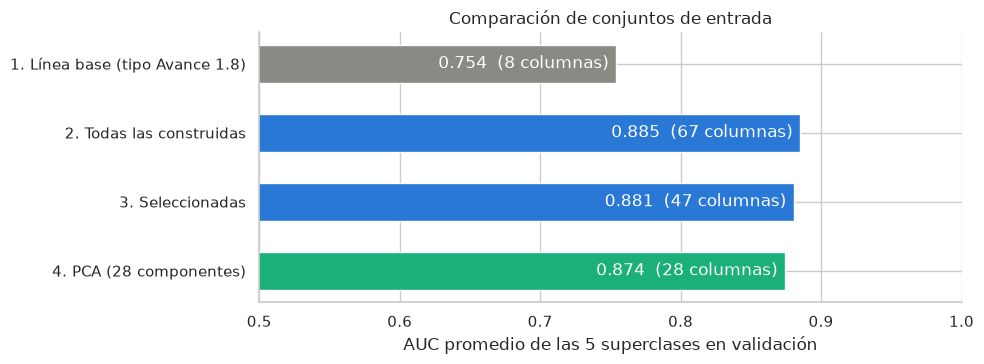

In [14]:
baseline_cols = ["hr_bpm", "rr_std_ms", "amp_II", "max_abs", "signal_std", "baseline_fraction"]
baseline_raw = X.loc[keep, baseline_cols]
baseline_power = PowerTransformer(method="yeo-johnson").fit(baseline_raw[train])
baseline = pd.DataFrame(baseline_power.transform(baseline_raw), index=baseline_raw.index, columns=baseline_cols)
baseline[["age_band", "female"]] = scaled[["age_band", "female"]]

input_sets = {"1. Línea base (tipo Avance 1.8)": baseline, "2. Todas las construidas": scaled[features],
              "3. Seleccionadas": scaled[selected], f"4. PCA ({n95} componentes)": components}
comparison = pd.DataFrame({name: validation_auc(frame, Y, train, val) for name, frame in input_sets.items()}).T
comparison["n_caracteristicas"] = comparison.n_caracteristicas.astype(int)
display(comparison.round(3))

fig, ax = plt.subplots(figsize=(10, 3.8))
bars = ax.barh(comparison.index[::-1], comparison.AUC_macro[::-1], color=[GRAY, BLUE, BLUE, AQUA][::-1], height=0.55)
for bar, value, n in zip(bars, comparison.AUC_macro[::-1], comparison.n_caracteristicas[::-1]):
    ax.text(value - 0.005, bar.get_y() + bar.get_height() / 2, f"{value:.3f}  ({n} columnas)", va="center",
            ha="right", color="white")
ax.set(xlim=(0.5, 1), xlabel="AUC promedio de las 5 superclases en validación", title="Comparación de conjuntos de entrada")
plt.tight_layout(); plt.show()

Qué vemos:

- Las características construidas mejoran mucho a la línea base: el AUC promedio pasa de 0.754 a
  0.885. La mayor ganancia está en STTC (de 0.70 a 0.90), justo donde las medidas de ST y T aportan
  información que los descriptores generales no tienen. La menor está en HYP (de 0.84 a 0.88),
  probablemente porque la amplitud general de la señal, que ya está en la línea base, refleja en parte
  el voltaje alto de la hipertrofia.
- Las 47 características seleccionadas logran 0.881, casi lo mismo que las 67 (0.885), con 30% menos
  columnas.
- Las 28 componentes del PCA logran 0.874: comprimen más, pero pierden un poco más de AUC y sus
  columnas ya no se pueden explicar a un cardiólogo directamente.
- El tiempo de entrenamiento es de fracciones de segundo en todos los casos. Con un modelo tan
  sencillo la ganancia en tiempo no es medible; la reducción importa más por almacenamiento,
  interpretación y estabilidad de los modelos que vendrán.

## 13. Guardar el conjunto preparado

Guardamos la tabla final con las características seleccionadas y escaladas para los tres conjuntos,
las etiquetas y el conjunto al que pertenece cada ECG. También guardamos la versión PCA y todos los
parámetros aprendidos en entrenamiento, para poder aplicar exactamente la misma preparación a datos
nuevos.

In [15]:
prepared = pd.concat([split.rename("conjunto"), scaled[selected], Y], axis=1)
prepared.to_csv(OUT / "caracteristicas_seleccionadas.csv")
pd.concat([split.rename("conjunto"), components, Y], axis=1).to_csv(OUT / "componentes_pca.csv")
X.to_csv(OUT / "caracteristicas_sin_escalar.csv")
comparison.to_csv(OUT / "comparacion_validacion.csv")
threshold_table.to_csv(OUT / "umbral_correlacion.csv")

parameters = {
    "dataset": "PTB-XL 1.0.3",
    "metadata_sha256": hashlib.sha256((PTBXL_DIR / "ptbxl_database.csv").read_bytes()).hexdigest(),
    "module_sha256": hashlib.sha256((ROOT / "ecg_experiment/eda/avance2_features.py").read_bytes()).hexdigest(),
    "versions": versions,
    "ecg_supervisados": int(keep.sum()), "candidatas": CANDIDATES, "casi_constantes": quasi_constant,
    "relevantes": relevant, "umbral_correlacion": CORR_THRESHOLD, "seleccionadas": selected,
    "medianas_entrenamiento": train_medians.round(6).to_dict(),
    "yeo_johnson": dict(zip(skewed, power.lambdas_.round(6).tolist())),
    "escalado_media": dict(zip(features, scaler.mean_.round(6).tolist())),
    "escalado_desviacion": dict(zip(features, scaler.scale_.round(6).tolist())),
    "pca_componentes": n95,
}
(OUT / "parametros_preparacion.json").write_text(json.dumps(parameters, indent=2, ensure_ascii=False))
display(prepared.groupby("conjunto").size().to_frame("ECG"))
print("Columnas de la tabla final:", prepared.shape[1], "| archivos en", OUT.relative_to(ROOT))

,ECG
conjunto,
entrenamiento,17083
prueba,2158
validación,2146


Columnas de la tabla final: 53 | archivos en outputs/eda/avance2


## 14. Resumen numérico

La siguiente tabla reúne, a partir de los resultados ejecutados arriba, las cifras en las que se basan
las conclusiones.

In [16]:
best = comparison.AUC_macro
recap = pd.Series({
    "ECG en la vista supervisada": f"{keep.sum():,}",
    "ECG de entrenamiento / validación / prueba": " / ".join(f"{(split == s).sum():,}" for s in ["entrenamiento", "validación", "prueba"]),
    "Medidas por ECG (globales + por derivación)": len(GLOBAL) + len(PER_LEAD),
    "Características candidatas (con las nuevas)": len(CANDIDATES),
    "Eliminadas por varianza": len(quasi_constant),
    "Eliminadas por relevancia (ANOVA / chi-cuadrado)": len(features) - len(relevant),
    "Eliminadas por correlación": len(removed),
    "Características seleccionadas": len(selected),
    "Componentes PCA para 95%": n95,
    "Variables transformadas con Yeo-Johnson": len(skewed),
    "AUC línea base": f"{best.iloc[0]:.3f}",
    "AUC todas las construidas": f"{best.iloc[1]:.3f}",
    "AUC seleccionadas": f"{best.iloc[2]:.3f}",
    "AUC PCA": f"{best.iloc[3]:.3f}",
})
display(recap.to_frame("valor"))

,valor
ECG en la vista supervisada,"21,387"
ECG de entrenamiento / validación / prueba,"17,083 / 2,146 / 2,158"
Medidas por ECG (globales + por derivación),52
Características candidatas (con las nuevas),68
Eliminadas por varianza,1
Eliminadas por relevancia (ANOVA / chi-cuadrado),5
Eliminadas por correlación,15
Características seleccionadas,47
Componentes PCA para 95%,28
Variables transformadas con Yeo-Johnson,45


## 15. Conclusiones

### Qué logramos

- Convertimos cada ECG de 60,000 números en una tabla de medidas con significado clínico: frecuencia,
  QRS, QT, desnivel ST, ondas R, S y T en cada derivación.
- Comprobamos que las medidas tienen sentido: el QRS separa los bloqueos de rama de los ECG normales, el
  QTc es mayor en QT largo, el índice de Sokolow-Lyon es mayor en hipertrofia y el eje calculado coincide
  con el anotado por cardiólogos.
- Construimos características nuevas con conocimiento médico (QTc, eje con seno y coseno, índices de
  hipertrofia, conteos de derivaciones con ST o T anormales) y discretizamos con umbrales clínicos.
  Varias de ellas están entre las más relevantes.
- Codificamos cada variable según su tipo: binaria para el sexo y las banderas, ordinal para los grupos de
  edad y one-hot para la categoría del eje.
- Reducimos la asimetría con Yeo-Johnson (de las transformaciones comparadas, la única que se puede
  aplicar a las 61 variables continuas) y estandarizamos, porque min-max se deforma con los valores
  extremos reales del ECG.
- Pasamos de 68 candidatas a 47 seleccionadas con tres filtros justificados: varianza (1 eliminada),
  relevancia con ANOVA y chi-cuadrado (5 eliminadas) y correlación (15 eliminadas). El umbral de
  correlación (0.80) se eligió con evidencia, no a ojo. El PCA comprime a 28 componentes y resultó mejor
  y mucho más rápido que el análisis factorial.
- Con un modelo sencillo, las características construidas suben el AUC promedio de 0.754 a 0.885 frente
  a descriptores generales como los del Avance 1.8. Las 47 seleccionadas mantienen ese nivel (0.881). El
  PCA pierde un poco más (0.874).

### Recomendación para la siguiente fase

Usar las características seleccionadas como entrada principal de los modelos clásicos, porque conservan
el desempeño y se pueden explicar al cardiólogo. Dejar la versión PCA como alternativa cuando se necesite
comprimir más.

### Conclusión de la fase de Preparación de los datos (CRISP-ML(Q))

En CRISP-ML(Q), la preparación de los datos tiene cuatro tareas: seleccionar, limpiar, construir y
estandarizar los datos, siempre con controles de calidad que reduzcan los riesgos para el modelo. En
nuestro proyecto:

- Seleccionar datos. Excluimos el ECG con una derivación plana y los 411 sin superclase, y descartamos
  las columnas que filtran la respuesta (reportes, códigos diagnósticos) o que describen el equipo y el
  lugar de grabación. Seleccionamos características con filtros de varianza, relevancia y correlación.
  El desequilibrio entre clases (NORM 44% frente a HYP 12%, según el Avance 1.8) se conserva a propósito:
  refleja la realidad, y se atenderá en el modelado con pesos por clase y métricas como el AUC, que no
  dependen de la proporción de cada clase.
- Limpiar datos. Redujimos el ruido de la señal con un filtro de 0.5 a 40 Hz y el latido mediano. Tratamos
  las edades ocultas sin inventar valores (grupos de edad), descartamos talla y peso por exceso de vacíos
  e imputamos los 5 valores faltantes con medianas de entrenamiento.
- Construir datos. Pasamos de la señal cruda a medidas clínicas y creamos características nuevas con
  conocimiento del dominio, discretizadas y codificadas según su tipo. No aplicamos aumento de datos
  (data augmentation): con 17 mil ECG de entrenamiento y modelos sobre características tabulares no hace
  falta en esta fase.
- Estandarizar datos. Aplicamos Yeo-Johnson y z-score con parámetros de entrenamiento, y guardamos
  esos parámetros para repetir la misma preparación en datos nuevos.
- Aseguramiento de calidad. Repetimos la cuenta del Avance 1.8 como control de integridad, validamos las
  medidas contra diagnósticos conocidos, ajustamos todo solo con entrenamiento para evitar fugas y dejamos
  intacto el fold 10 para la evaluación final.

El resultado de la fase es un conjunto de datos listo para el modelado, reproducible y explicable.

### Limitaciones

- Las medidas provienen de nuestro propio algoritmo. Son aproximaciones validadas por grupos, no
  mediciones certificadas, y conviene que el cardiólogo del proyecto las revise. En 49 ECG ruidosos
  (0.2%) el algoritmo no encontró el final del QRS.
- PTB-XL es una población mayor (mediana de 61 años) que la de estudiantes. La edad resultó relevante
  aquí, pero entre estudiantes casi todos caerán en el grupo `< 30` y la edad aportará poco.
- La elevación del ST es frecuente y normal en hombres jóvenes. Las características de ST deben
  revisarse con el cardiólogo antes de usarlas para cribar estudiantes.
- Algunos pacientes tienen varios ECG; los filtros los tratan como independientes. Por eso decidimos con
  tamaños de efecto y no con p-valores.
- El umbral de correlación se eligió con el fold de validación, así que el AUC de esa comparación es
  algo optimista. La medida honesta llegará con el fold 10 en la fase de evaluación.